In [1]:
import pandas as pd

df = pd.read_csv(
    "../data/processed/willow_and_wick_sales_2025_clean.csv",
    parse_dates=["order_date"],
)

print(df.shape)
df.dtypes

(620, 13)


order_id                    str
order_date       datetime64[us]
customer_id                 str
product                     str
category                    str
quantity                  int64
unit_price              float64
discount_code               str
region                      str
sales_channel               str
is_return                  bool
revenue                 float64
net_revenue             float64
dtype: object

In [2]:
monthly = (
    df.groupby(df["order_date"].dt.to_period("M"))["net_revenue"]
    .sum()
    .round(2)
)

monthly


order_date
2025-01     812.44
2025-02    1267.98
2025-03    1318.74
2025-04    1246.88
2025-05    1558.56
2025-06    1172.46
2025-07     952.28
2025-08    1358.76
2025-09    1288.27
2025-10    3619.42
2025-11    3696.83
2025-12    2840.32
Freq: M, Name: net_revenue, dtype: float64

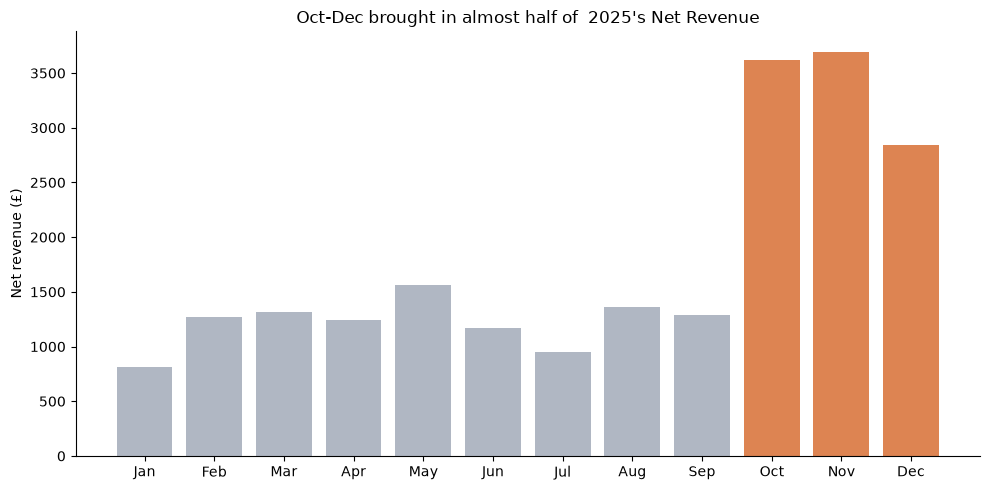

In [7]:
import matplotlib.pyplot as plt

labels = monthly.index.strftime("%b")
colors = ["#DD8452" if m.month>= 10 else "#B0B7C3" for m in monthly.index]

fig, ax = plt.subplots(figsize=(10,5))
ax.bar(labels, monthly.values, color=colors)


ax.set_title("Oct-Dec brought in almost half of  2025's Net Revenue")
ax.set_ylabel("Net revenue (£)")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=0)
plt.tight_layout()

from pathlib import Path
Path("../outputs/charts").mkdir(parents=True, exist_ok=True)
fig.savefig("../outputs/charts/01_monthly_revenue.png", dpi=150)
plt.show()

In [8]:
products = (
    df.groupby("product")["net_revenue"]
    .sum()
    .sort_values(ascending=False)
    .round(2)
)

products

product
Cotton Throw Blanket         3447.00
Woven Storage Basket         3275.15
Macrame Wall Hanging         2482.35
Soy Candle Gift Set          2377.03
Bamboo Serving Board         1821.40
Linen Cushion Cover          1525.70
Reed Diffuser                1517.21
Scented Candle - Lavender    1139.21
Scented Candle - Vanilla     1013.30
Ceramic Mug - Sage            938.73
Ceramic Mug - Sand            883.11
Room Spray - Citrus           712.75
Name: net_revenue, dtype: float64

In [9]:
sales_only = df[~df["is_return"]]

product_table = (
    sales_only.groupby("product")
    .agg(
        units_sold=("quantity", "sum"),
        price=("unit_price", "first"),
        net_revenue=("net_revenue", "sum"),
    )
    .sort_values("net_revenue", ascending=False)
    .round(2)
)

product_table

,units_sold,price,net_revenue
product,,,
Cotton Throw Blanket,82,45.00,3561.75
Woven Storage Basket,113,31.00,3389.85
Macrame Wall Hanging,72,39.00,2677.35
Soy Candle Gift Set,77,34.50,2546.08
Bamboo Serving Board,69,28.00,1846.60
Linen Cushion Cover,74,22.00,1563.10
Reed Diffuser,80,19.99,1537.20
Scented Candle - Lavender,83,14.99,1181.18
Scented Candle - Vanilla,72,14.99,1026.04


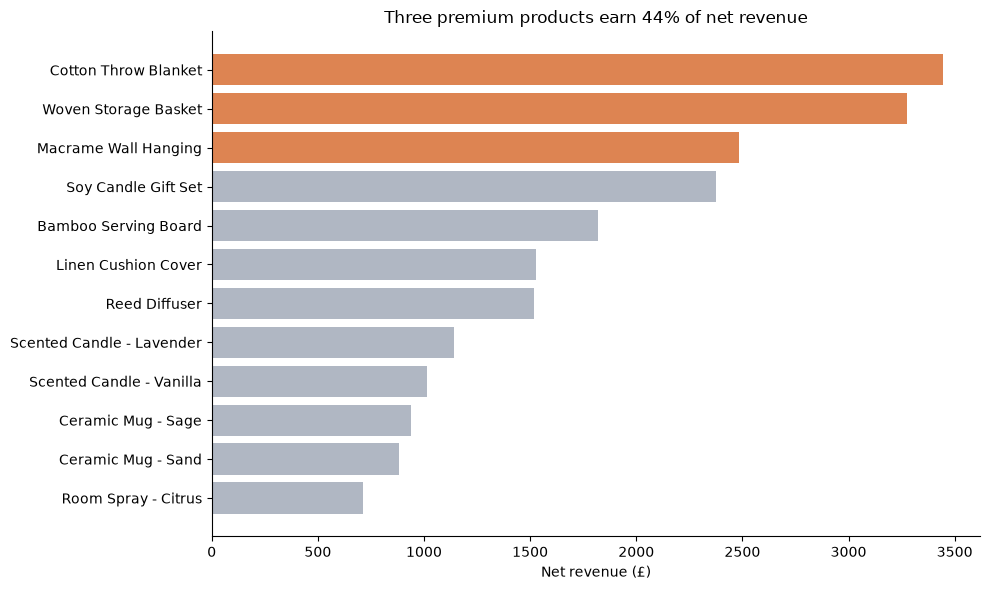

In [11]:
fig, ax = plt.subplots(figsize=(10,6))

top3 = products.index[:3]
colors = ["#DD8452" if p in top3 else "#B0B7C3" for p in products.index]

ax.barh(products.index, products.values, color=colors)
ax.invert_yaxis()

ax.set_title("Three premium products earn 44% of net revenue")
ax.set_xlabel("Net revenue (£)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

fig.savefig("../outputs/charts/02_product_revenue.png", dpi=150)
plt.show()

In [13]:
categories = (
    df.groupby("category")["net_revenue"]
    .sum()
    .sort_values(ascending=False)
    .round(2)
)

category_share = (categories / categories.sum() * 100).round(1)

pd.DataFrame({"net_revenue": categories, "share_%": category_share})
              

,net_revenue,share_%
category,,
Textiles,4972.70,23.5
Candles,4529.54,21.4
Kitchen,3643.24,17.2
Storage,3275.15,15.5
Decor,2482.35,11.7
Fragrance,2229.96,10.6


In [14]:
df.groupby("category")["product"].unique()

category
Candles      [Scented Candle - Vanilla, Soy Candle Gift Set...
Decor                                   [Macrame Wall Hanging]
Fragrance                 [Reed Diffuser, Room Spray - Citrus]
Kitchen      [Bamboo Serving Board, Ceramic Mug - Sand, Cer...
Storage                                 [Woven Storage Basket]
Textiles           [Linen Cushion Cover, Cotton Throw Blanket]
Name: product, dtype: object

In [15]:
def summarise(column):
    table = (
        df.groupby(column)
        .agg(orders=("order_id", "count"), net_revenue=("net_revenue", "sum"))
        .sort_values("net_revenue", ascending=False)
    )
    table["share_%"] = table["net_revenue"] / table["net_revenue"].sum() * 100
    table["avg_order_£"] = table["net_revenue"] / table["orders"]
    return table.round(2)

summarise("region")

,orders,net_revenue,share_%,avg_order_£
region,,,,
London,190,6382.82,30.20,33.59
South East,138,4701.35,22.25,34.07
North West,76,2974.86,14.08,39.14
Scotland,73,2310.09,10.93,31.65
Midlands,66,2185.81,10.34,33.12
Wales,53,1784.27,8.44,33.67
Unknown,24,793.74,3.76,33.07


In [16]:
summarise("sales_channel")

,orders,net_revenue,share_%,avg_order_£
sales_channel,,,,
Website,335,11766.68,55.68,35.12
Etsy,193,6856.04,32.44,35.52
Instagram,92,2510.22,11.88,27.28
